# From command to image: a walk through the scan-path pipeline

Every scan starts with a plan. Go here, then here, then here. The microscope never does
exactly that. The scanner lags behind fast moves, a piezo remembers which way it was
going, the sample drifts, and the image on the screen is drawn as if the probe had gone
precisely where it was told.

This notebook follows that gap from start to finish. We take a scan path, hand it to a
model of the instrument, see where the probe really went, score the result, look at the
image a user would get, and then let an optimizer choose a better path. Along the way
every path family we currently have gets its turn.

```
 path family + parameters ──► generator ──► commanded trajectory
 commanded trajectory     ──► instrument model ──► realized trajectory
 commanded + realized + sample ──► metrics and imaging ──► scores
 scores ──► optimizer ──► next parameters  (and round again)
```

Two pieces of code meet here:

* **`scanpath`**, our package in this `scanpath_core` folder: the shared records, the
  plug-in registries and the optimizer loop.
* **`instrument_transfer`**, Kalinin's package: a catalog of 37 path families, an SPM
  scanner model with hysteresis and creep, distortion metrics and a checkerboard. It is
  read straight from your clone of his GitHub repo (the `ScanPath` folder next to
  `microscopy scan path`), which is used as a reference and never written to.
  `scanpath/kalinin.py` is the short bridge that registers his pieces as plug-ins.

Run it top to bottom; the whole thing takes a couple of minutes on a laptop.

In [1]:
import sys, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

CORE = Path.cwd().parent                                   # scanpath_core (run from notebooks/)
REFERENCE = Path.cwd().parents[2] / "ScanPath" / "src"     # Kalinin's repo; edit if yours lives elsewhere
sys.path.insert(0, str(CORE))
sys.path.append(str(REFERENCE))
sys.dont_write_bytecode = True                              # read his repo, never write into it

import scanpath as sp
from scanpath.kalinin import KALININ_CLASS               # importing this registers his plug-ins
from instrument_transfer.imaging import make_checkerboard
from instrument_transfer.instruments import (spm_transfer_function,
                                             build_spm_params_hysteresis_dominated)

# one look for every figure
BLUE, ORANGE, AQUA, VIOLET, MAGENTA, GREEN = ("#2a78d6", "#eb6834", "#1baf7a",
                                              "#6250d6", "#e87ba4", "#008300")
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 2, "font.size": 10,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})

def family_group(name):
    # 'ours' for scanpath's own families, otherwise Kalinin's class label
    return "class " + KALININ_CLASS[name] if name in KALININ_CLASS else "ours"

GROUP_COLOR = {"ours": BLUE, "class 0": ORANGE, "class 0+0": AQUA, "class 1": VIOLET,
               "class 1+0": MAGENTA, "class 2": GREEN}
def label(name):
    # a few names exist in both packages (raster, spiral, ...), so say whose is whose
    plain = name.removeprefix("k_")
    if plain not in sp.PATHS or "k_" + plain not in sp.PATHS:
        return plain
    return f"{plain} (Kalinin)" if name.startswith("k_") else f"{plain} (ours)"

## 1. Ground rules: everyone gets the same budget

Comparing scan paths only makes sense if they play by the same rules. So every path here
gets the same field of view, the same scan time and the same number of samples. That is
the `Budget`. Path length and speed are not forced to match (you can't fix all of them at
once), but we will keep an eye on them.

We also need something to look at. A `Sample` is just an ideal image covering the field.
We'll use two: a field of soft particles, and Kalinin's checkerboard, whose straight
edges make distortion very easy to see.

field of view : 100 nm
scan time     : 1.0 s
samples       : 20,000 (20 kHz)


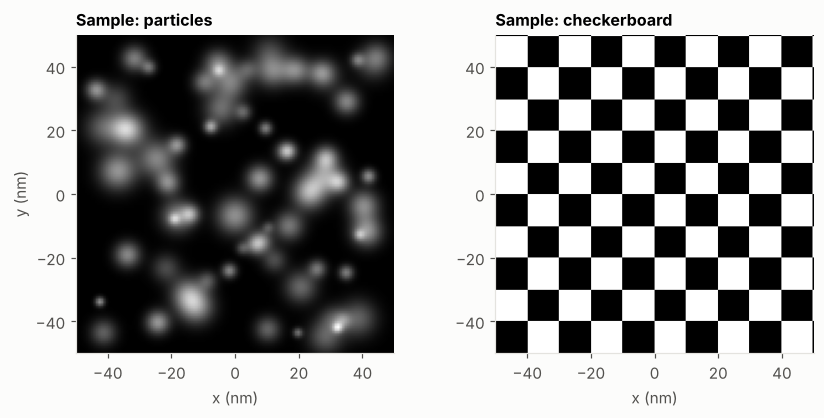

In [2]:
budget = sp.Budget(fov_nm=100, duration_s=1.0, rate_hz=20_000)
particles = sp.Sample.synthetic(budget.fov_nm, seed=0)
checkerboard = sp.Sample(make_checkerboard(size=256, n_checks_x=10, n_checks_y=10), budget.fov_nm)

print(f"field of view : {budget.fov_nm:.0f} nm")
print(f"scan time     : {budget.duration_s:.1f} s")
print(f"samples       : {budget.n:,} ({budget.rate_hz/1000:.0f} kHz)")

extent = [-budget.fov_nm / 2, budget.fov_nm / 2] * 2
fig, axes = plt.subplots(1, 2, figsize=(8, 3.8))
for ax, sample, title in zip(axes, (particles, checkerboard), ("particles", "checkerboard")):
    ax.imshow(sample.image, extent=extent, origin="lower", cmap="gray")
    ax.set_title(f"Sample: {title}"); ax.set_xlabel("x (nm)"); ax.grid(False)
axes[0].set_ylabel("y (nm)")
plt.tight_layout(); plt.show()

## 2. Who's in the cast

Each of the three replaceable stages keeps a registry: a dictionary from a name to a
function. Adding a path, an instrument or a metric means writing one function and putting
a decorator on it. Here is everything that's currently registered.

In [3]:
from collections import Counter

groups = Counter(family_group(name) for name in sp.PATHS)
print(f"{len(sp.PATHS)} path families:")
for group in GROUP_COLOR:
    print(f"   {group:10s} {groups[group]:3d}")
print(f"\n{len(sp.INSTRUMENTS)} instrument models: {', '.join(sp.INSTRUMENTS)}")
print(f"\n{len(sp.METRICS)} metrics:")
for name, fn in sp.METRICS.items():
    better = "higher" if fn.higher_is_better else "lower"
    print(f"   {name:24s} {better:6s} is better   {fn.__doc__.strip().splitlines()[0]}")

52 path families:
   ours        15
   class 0     12
   class 0+0    6
   class 1      7
   class 1+0    5
   class 2      7

9 instrument models: ideal, lowpass, resonant, drift, noise, stage_moves, creep, chain, spm_hysteresis

23 metrics:
   rms_error_nm             lower  is better   RMS distance between commanded and realized positions.
   max_error_nm             lower  is better   Worst-case distance between commanded and realized positions.
   local_misalignment_nm    lower  is better   RMS left after the best overall shift and rotation (shape error), nm.
   placement_error_p99_nm   lower  is better   99th percentile of |realized - commanded|: the worst-placed samples, nm.
   coverage                 higher is better   Fraction of image pixels with a realized measurement within one pixel pitch.
   max_gap_nm               lower  is better   Largest distance from any pixel to the nearest realized measurement.
   image_nrmse              lower  is better   Image error as the use

Kalinin sorts his paths into classes. **Class 0** paths are single smooth curves (rasters,
spirals, Lissajous figures, roses). **0+0** takes one of those and adds a small local
wobble along it. **Class 1** paths are recursive (Hilbert, Morton, recursive 2×2
patterns), **1+0** adds a wobble on top of a recursive path, and **class 2** recurses on a
3×3 grid (Peano and friends). Our own fifteen families sit beside them: three driven curves
(raster, spiral, Lissajous), five shapes from the team's loop prototype (serpentine,
radial, Hilbert, sparse, hybrid), four from the team's workflow notebook (strokes,
closed loops, rose, and a pulse lattice that measures only while parked) and three
pixel-list scans from Palos et al. 2026 (spiral in or out, N-sequential, random order).

## 3. The generator: every path family, side by side

The generator's job is simple. Given a family name and its parameters, it returns the
**commanded trajectory**: where we ask the probe to be at each moment. It's a
`Trajectory` with a time axis `t` and positions `xy` in nanometres.

Kalinin's generators draw their paths with their own number of points. The bridge treats
his point index as time and resamples it onto our budget, so all 45 families below run for
exactly one second with 20,000 samples. Colour marks the class.

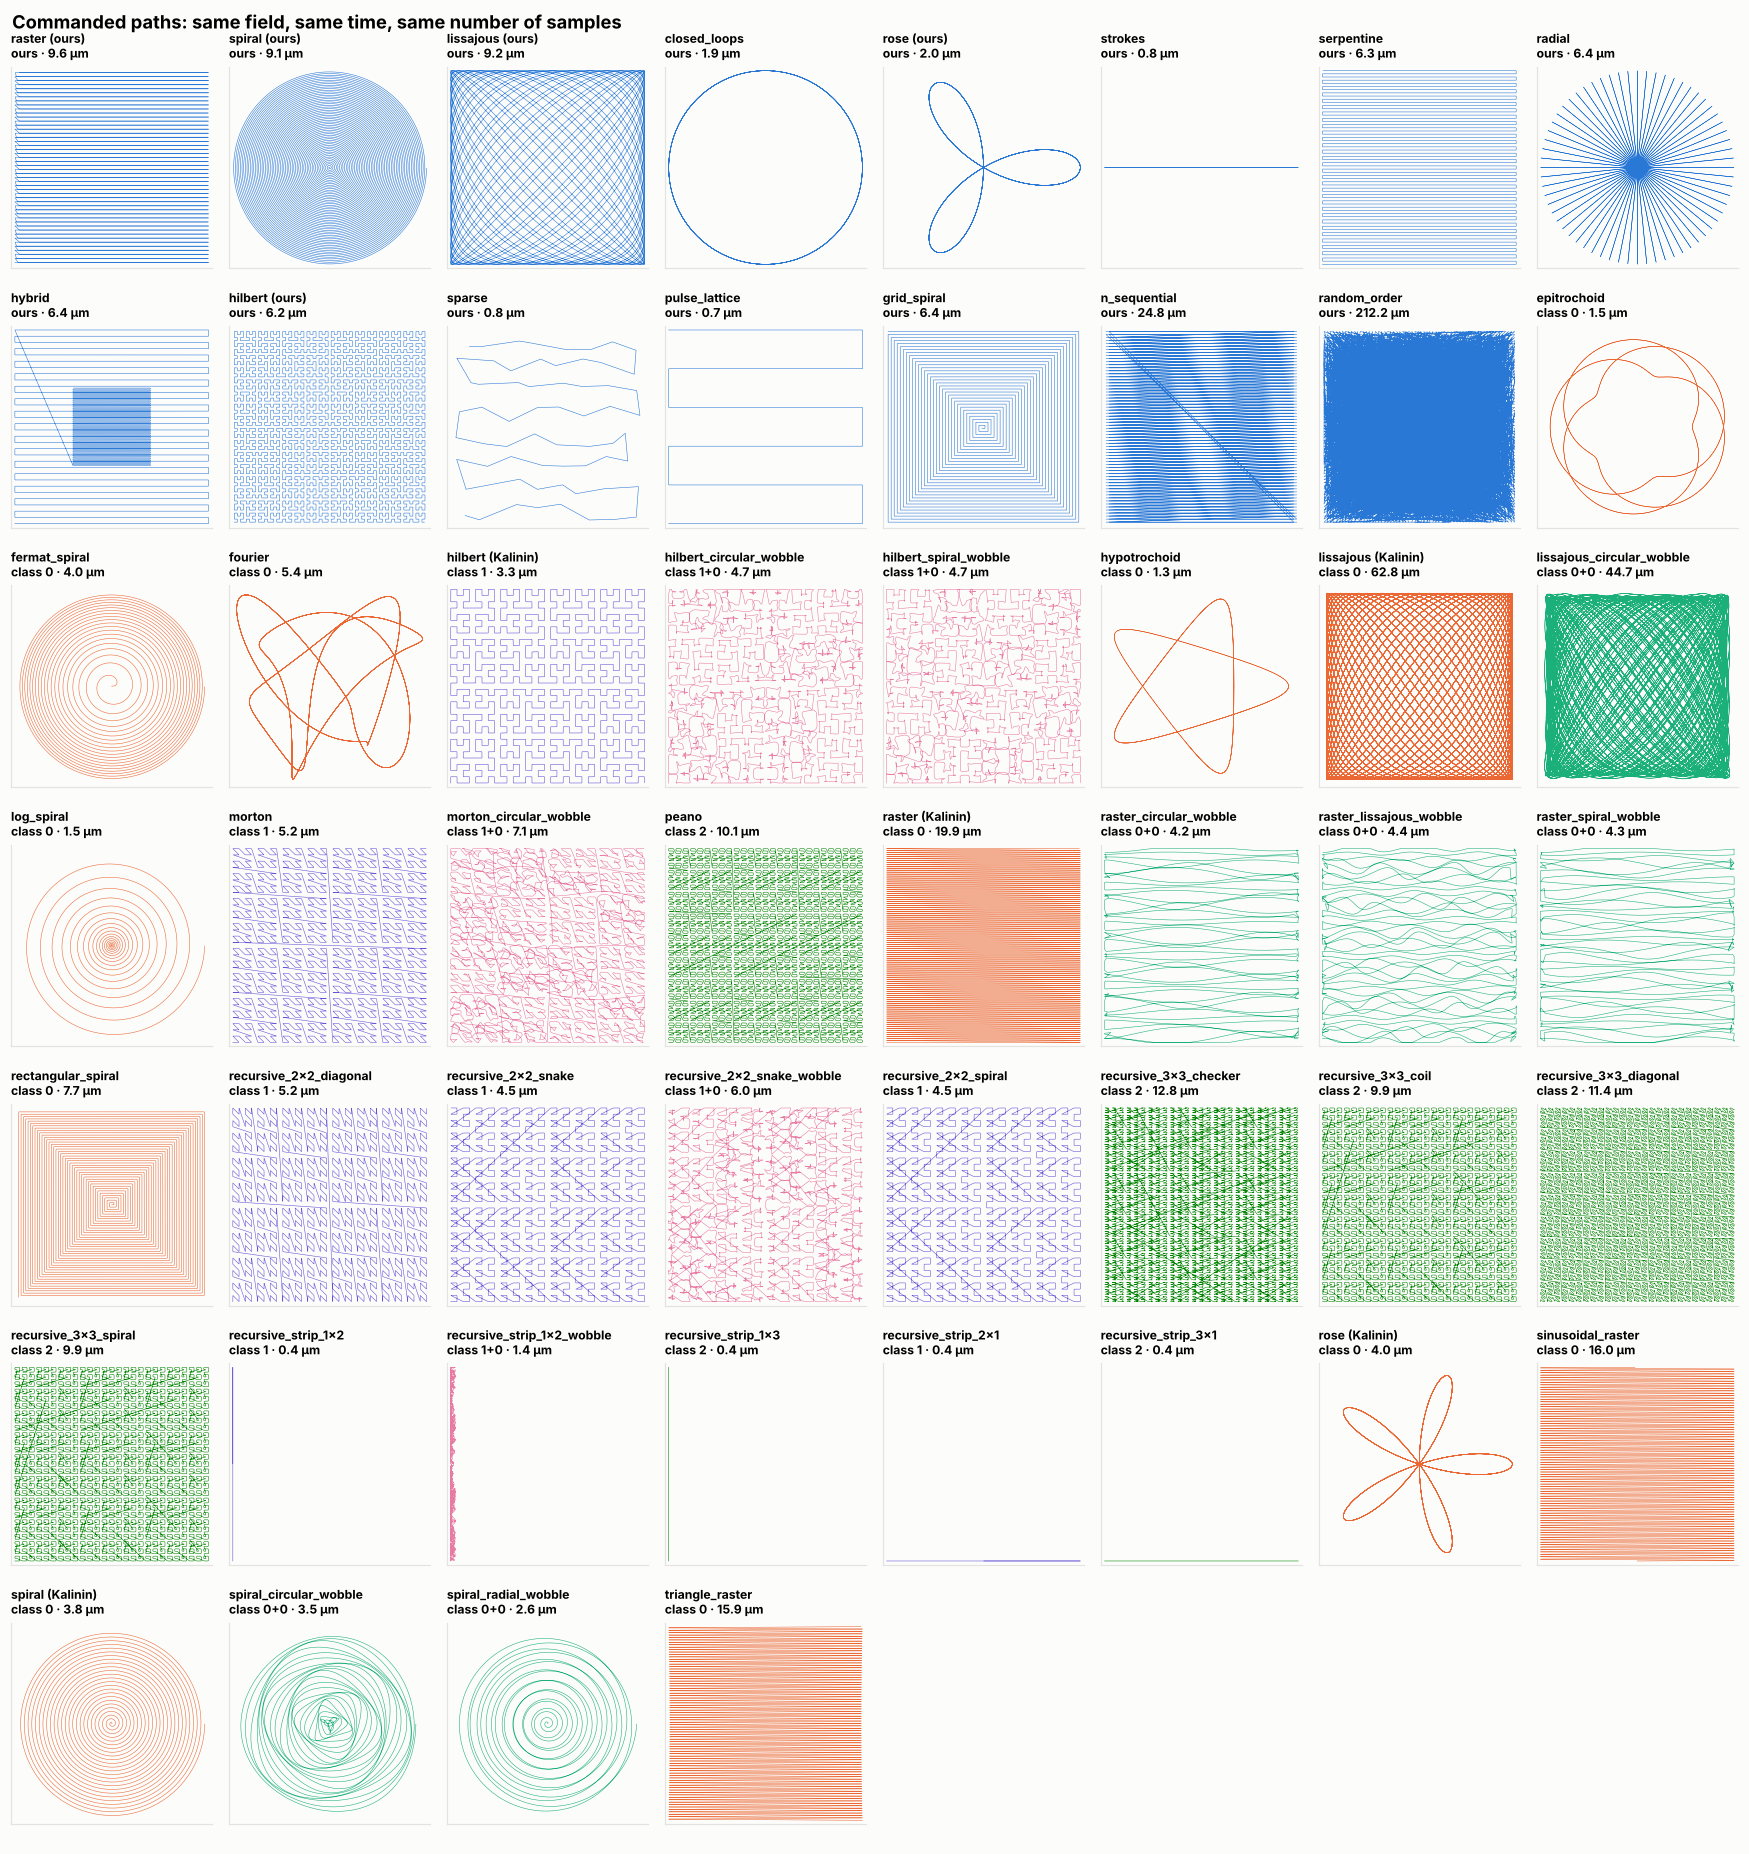

In [4]:
names = list(sp.PATHS)
commanded = {name: sp.make_path(name, budget) for name in names}
length_um = {name: sp.evaluate(c, c, particles, ["path_length_um"])["path_length_um"]
             for name, c in commanded.items()}

cols = 8
rows = int(np.ceil(len(names) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(16, 2.45 * rows))
for ax, name in zip(axes.flat, names):
    group = family_group(name)
    ax.plot(*commanded[name].xy.T, lw=0.35, color=GROUP_COLOR[group])
    ax.set_title(f"{label(name)}\n{group} · {length_um[name]:.1f} µm", fontsize=8)
    ax.set_xlim(-52, 52); ax.set_ylim(-52, 52); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
for ax in list(axes.flat)[len(names):]:
    ax.axis("off")
fig.suptitle("Commanded paths: same field, same time, same number of samples",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

A few things stand out straight away.

* **The four `recursive_strip_*` families are just straight lines.** They subdivide only
  one axis, so the other coordinate never changes. That's a bug in the generator, not a
  feature, and it's worth fixing upstream.
* **Kalinin's default `lissajous` goes round the same closed curve eight times**
  (`n_periods=8` with whole-number frequencies), so seven-eighths of its samples repeat
  ground it has already covered.
* **Path lengths are all over the place.** The same scan time hides very different speeds.
  The next plot makes that concrete.

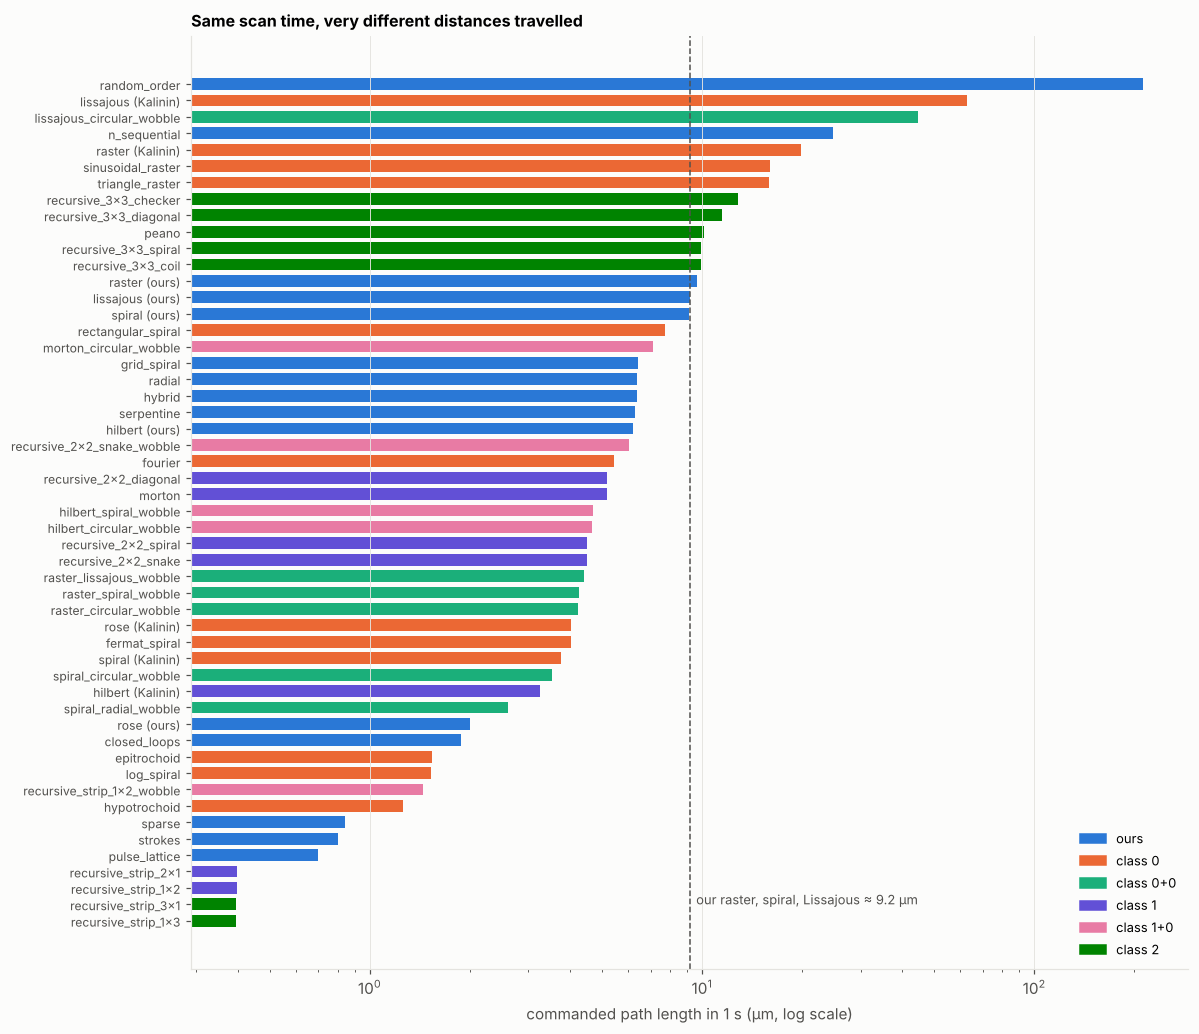

In [5]:
order = sorted(names, key=length_um.get)
fig, ax = plt.subplots(figsize=(11, 9.5))
ax.barh(range(len(order)), [length_um[n] for n in order],
        color=[GROUP_COLOR[family_group(n)] for n in order], height=0.72)
ax.set_yticks(range(len(order)), [label(n) for n in order], fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("commanded path length in 1 s (µm, log scale)")
ax.axvline(9.2, color=INK2, lw=1, ls="--")
ax.text(9.6, 1, "our raster, spiral, Lissajous ≈ 9.2 µm", color=INK2, fontsize=8.5)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLOR.values()]
ax.legend(handles, GROUP_COLOR.keys(), loc="lower right", fontsize=8.5)
ax.grid(axis="y", visible=False)
ax.set_title("Same scan time, very different distances travelled")
plt.tight_layout(); plt.show()

Path length is roughly "how hard we're driving the scanner". Kalinin's default Lissajous
travels about seven times further in the same second than our raster, spiral and
Lissajous defaults. A path like
that covers the field more densely, but it also stresses the instrument far more. So when we rank paths later, we have to keep this in mind,
and for a fair head-to-head we'll pick parameters that put the contenders at similar
lengths.

## 4. The instrument model: what the microscope actually does

The instrument model takes the commanded trajectory and returns the **realized
trajectory**, on the same time axis. It never sees the sample; it only knows about the
hardware. We have four models:

| model | what it represents |
|---|---|
| `ideal` | perfect tracking. Useful as a baseline. |
| `lowpass` | a scanner with limited bandwidth (here 1.5 kHz): it lags and rounds corners |
| `resonant` | a mass-on-a-spring scanner, like a piezo tube: it overshoots and rings |
| `spm_hysteresis` | Kalinin's SPM model: hysteresis, plus optional creep, drift and nonlinearity |

Let's give all four the same raster and watch one line turnaround.

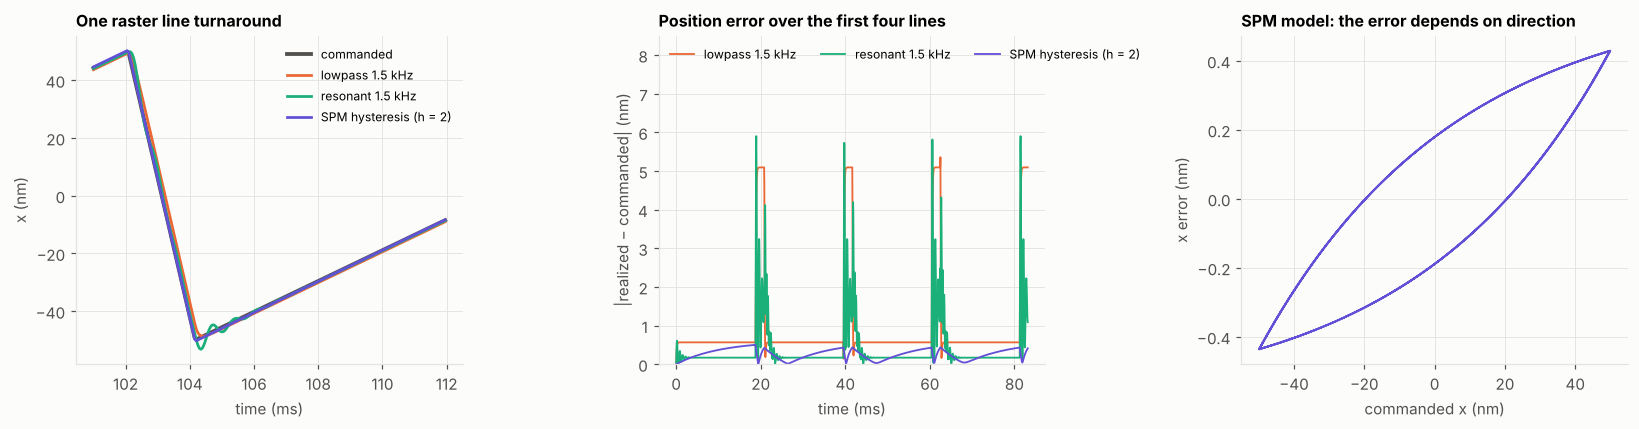

In [6]:
models = {
    "commanded": None,
    "lowpass 1.5 kHz": ("lowpass", {"bandwidth_hz": 1500}),
    "resonant 1.5 kHz": ("resonant", {"resonance_hz": 1500, "damping": 0.15}),
    "SPM hysteresis (h = 2)": ("spm_hysteresis", {"hysteresis_strength": 2.0}),
}
colors = [INK2, ORANGE, AQUA, VIOLET]
raster = commanded["raster"]
realized = {lab: raster if m is None else sp.simulate(raster, m[0], **m[1])
            for lab, m in models.items()}

line = int(budget.n / 48)                      # samples per raster line
window = slice(5 * line - 60, 5 * line + 160)
fig, (a, b, c) = plt.subplots(1, 3, figsize=(15, 4))
for (lab, traj), color in zip(realized.items(), colors):
    a.plot(traj.t[window] * 1e3, traj.xy[window, 0], color=color, label=lab,
           lw=2.5 if lab == "commanded" else 1.8)
a.set_xlabel("time (ms)"); a.set_ylabel("x (nm)")
a.set_title("One raster line turnaround"); a.legend(fontsize=8)

for (lab, traj), color in list(zip(realized.items(), colors))[1:]:
    err = np.linalg.norm(traj.xy - raster.xy, axis=1)
    b.plot(raster.t[:4 * line] * 1e3, err[:4 * line], color=color, lw=1.2, label=lab)
b.set_xlabel("time (ms)"); b.set_ylabel("|realized − commanded| (nm)")
b.set_ylim(0, 8.5); b.set_title("Position error over the first four lines")
b.legend(fontsize=8, ncol=3, loc="upper left")

spm = realized["SPM hysteresis (h = 2)"]
part = slice(10 * line, 14 * line)
c.plot(raster.xy[part, 0], spm.xy[part, 0] - raster.xy[part, 0], color=VIOLET, lw=1.2)
c.set_xlabel("commanded x (nm)"); c.set_ylabel("x error (nm)")
c.set_title("SPM model: the error depends on direction")
plt.tight_layout(); plt.show()

Three quite different personalities. The low-pass scanner simply runs late: during each
line it trails the command by a fixed amount, and after the fast flyback it takes a while
to catch up. The resonant scanner is quicker on average but overshoots and rings after the
sharp turn. Kalinin's hysteresis model behaves differently again. Its error doesn't care how
fast we move, only which way. The right-hand panel shows the classic hysteresis loop: going
right, the probe sits on one side of the command; coming back, it sits on the other.

His model can also hand back its internal state, which is handy when someone wants to
calibrate it against a real instrument later:

In [7]:
unit = raster.xy / budget.fov_nm + 0.5            # his model works in the unit box
params = build_spm_params_hysteresis_dominated(hysteresis_strength=2.0, other_distortion_scale=0.0)
_, parts = spm_transfer_function(unit, dt=1.0, params=params, return_components=True)
print("internal state returned:", ", ".join(parts))
print(f"hysteresis state range in x: {np.ptp(parts['hysteresis_state'][:, 0]):.3f} (unit-box units)")

internal state returned: scanner_state, quasi_static_target, hysteresis_state, creep_state, drift_state, line_jitter
hysteresis state range in x: 0.156 (unit-box units)


## 5. Metrics: turning a run into numbers

The evaluator takes three things: the commanded trajectory, the realized trajectory and
the sample. Every metric has that same signature and returns one number, so they can be
mixed and matched freely. We deliberately keep them separate. Squashing them into a single
score is a decision to make out loud later, not something to hide inside the code.

Here is one run, a 29/30 Lissajous on the hysteresis scanner, with every metric.

In [8]:
run = sp.run(("lissajous", {"nx": 29, "ny": 30}), ("spm_hysteresis", {"hysteresis_strength": 2.0}),
             budget=budget, sample=particles)
print(f"{'metric':26s}{'value':>10s}   meaning")
for name, value in run.scores.items():
    print(f"{name:26s}{value:10.3f}   {sp.METRICS[name].__doc__.strip().splitlines()[0]}")

metric                         value   meaning
rms_error_nm                   0.383   RMS distance between commanded and realized positions.
max_error_nm                   0.557   Worst-case distance between commanded and realized positions.
local_misalignment_nm          0.383   RMS left after the best overall shift and rotation (shape error), nm.
placement_error_p99_nm         0.525   99th percentile of |realized - commanded|: the worst-placed samples, nm.
coverage                       0.798   Fraction of image pixels with a realized measurement within one pixel pitch.
max_gap_nm                     1.863   Largest distance from any pixel to the nearest realized measurement.
image_nrmse                    0.161   Image error as the user sees it, relative to the ideal image's contrast.
image_correlation              0.987   Pearson correlation between the image the user sees and the ideal image.
image_nrmse_oracle             0.143   Image error if the true probe positions were known

Read these in groups. **Trajectory error** (`rms_error_nm`, `max_error_nm`) says how far
the probe strayed. **Coverage** (`coverage`, `max_gap_nm`) says whether it visited the
whole field. **Image error** (`image_nrmse`) is the one users feel, and comparing it with
`image_nrmse_oracle` splits it into two parts: what we lose because we sampled sparsely,
and what we lose because we drew the data in the wrong place. **Path length and speed**
are the fairness check from section 3. Kalinin's two metrics look at the *shape* of the
error: `k_distortion_roughness` is large when neighbouring points are pushed in different
directions, which no simple calibration can undo.

The metrics from the loop prototype add a few more views. `local_misalignment_nm` is the
error left after the best shift and rotation, and `placement_error_p99_nm` is the worst
1% of samples. `feature_position_error_nm` asks where known features end up in the
image. `noise_sensitivity_nm` reruns the instrument to see how much a repeat scan moves
(zero here, because this scanner model has no randomness). `stage_moves` and
`switch_confidence` count coarse-stage moves; they are trivially 0 and 1 in a 100 nm field
that never leaves the piezo's range, and matter for the 20 µm fields in example 04.

## 6. Imaging: what the user would actually see

Numbers are fine, but people look at images. Here's how the image comes together. The
detector reads the signal wherever the probe *really* was. The software, not knowing any
better, places each reading where the probe was *told* to be. Any difference between the
two shows up as a warped image.

The checkerboard makes this very visible. Each row below is one path on the hysteresis
scanner (turned up to h = 4 so the effect is easy to see). The first column is what the
user gets; the second is what they would get if they knew the true positions; the third is
the difference from the true checkerboard.

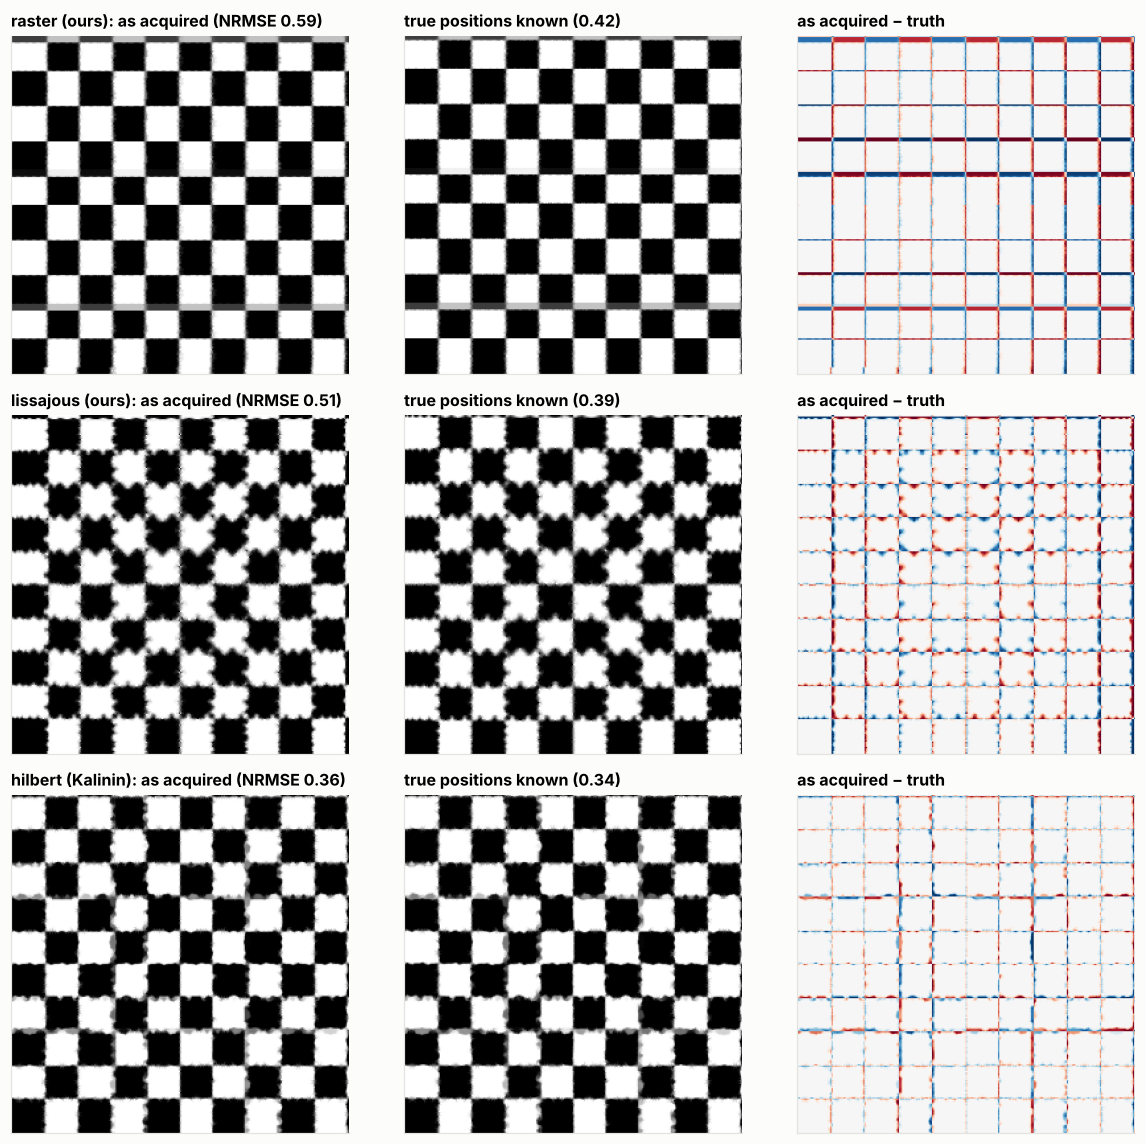

In [9]:
strong = ("spm_hysteresis", {"hysteresis_strength": 4.0})
showcase = [("raster", {}), ("lissajous", {"nx": 29, "ny": 30}), ("k_hilbert", {"order": 6})]

fig, axes = plt.subplots(len(showcase), 3, figsize=(11, 3.5 * len(showcase)))
for row, (name, params) in zip(axes, showcase):
    cmd = sp.make_path(name, budget, **params)
    real = sp.simulate(cmd, *strong[:1], **strong[1])
    seen = sp.image_as_acquired(cmd, real, checkerboard)
    known = sp.image_as_acquired(cmd, real, checkerboard, positions="realized")
    nrmse = sp.evaluate(cmd, real, checkerboard, ["image_nrmse", "image_nrmse_oracle"])
    row[0].imshow(seen, extent=extent, origin="lower", cmap="gray")
    row[0].set_title(f"{label(name)}: as acquired (NRMSE {nrmse['image_nrmse']:.2f})")
    row[1].imshow(known, extent=extent, origin="lower", cmap="gray")
    row[1].set_title(f"true positions known ({nrmse['image_nrmse_oracle']:.2f})")
    row[2].imshow(seen - checkerboard.image, extent=extent, origin="lower", cmap="RdBu_r",
                  vmin=-1, vmax=1)
    row[2].set_title("as acquired − truth")
    for ax in row:
        ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

Look at the raster first. Its difference map is dominated by horizontal stripes, and they
are there in the middle column too: with 48 lines across ten checks, some lines land right
on a check edge and blur it, whether or not we know the positions. That is a sampling
problem, not a scanner problem. The scanner's contribution is the gap between the first two
columns (0.59 against 0.42), visible as thin fringes along the vertical edges. The Lissajous
image has wavy edges from its crossing pattern, and loses a similar amount to the scanner.
The Hilbert curve wanders in small blocks, and the scanner barely matters for it (0.36
against 0.34): neighbouring points are visited close together in time, so they are
displaced together.

So there are really two questions for any path. How well does it *sample* the field, and
how much does the instrument *mislabel* the samples? The metrics `image_nrmse_oracle` and
`image_nrmse` separate the two.

## 7. Everyone through the same pipe

Now the whole cast, one at a time, through the same instrument (hysteresis, h = 2) on the
particle sample. This is the part that would have needed over fifty scripts before; here it's
one loop.

In [10]:
keys = ["image_nrmse", "rms_error_nm", "k_distortion_roughness", "coverage", "path_length_um"]
scanner = ("spm_hysteresis", {"hysteresis_strength": 2.0})
start = time.time()
board = []
for name in names:
    scores = sp.run(name, scanner, keys, budget, particles).scores
    board.append({"family": name, "group": family_group(name), **scores})
print(f"{len(board)} families scored in {time.time() - start:.0f} s\n")

board.sort(key=lambda r: r["image_nrmse"])
print(f"{'family':28s}{'group':>11s}" + "".join(f"{k:>24s}" for k in keys))
for r in board[:10] + [None] + board[-5:]:
    if r is None:
        print("   ...")
        continue
    print(f"{label(r['family']):28s}{r['group']:>11s}" + "".join(f"{r[k]:24.3f}" for k in keys))

52 families scored in 41 s

family                            group             image_nrmse            rms_error_nm  k_distortion_roughness                coverage          path_length_um
recursive_3x3_diagonal          class 2                   0.056                   0.095                   1.815                   0.999                  11.447
peano                           class 2                   0.067                   0.095                   1.716                   0.985                  10.113
recursive_3x3_coil              class 2                   0.070                   0.095                   1.948                   0.985                   9.931
recursive_3x3_spiral            class 2                   0.070                   0.095                   1.948                   0.985                   9.931
recursive_3x3_checker           class 2                   0.082                   0.108                   2.478                   0.946                  12.813
sinusoidal_r

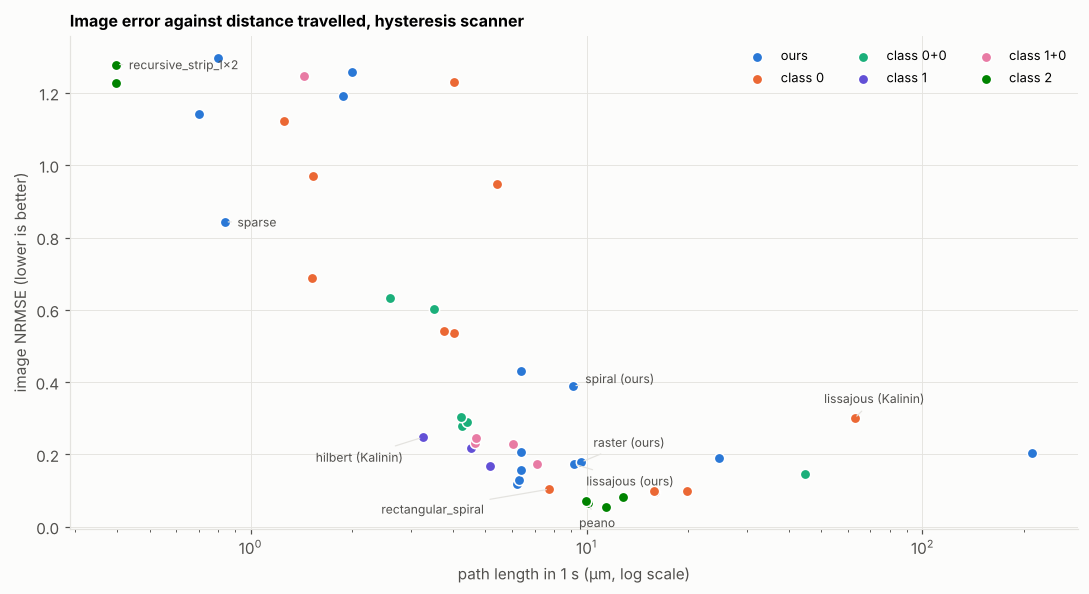

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for group, color in GROUP_COLOR.items():
    pts = [r for r in board if r["group"] == group]
    ax.scatter([r["path_length_um"] for r in pts], [r["image_nrmse"] for r in pts],
               s=46, color=color, label=group, edgecolor="white", linewidth=1, zorder=3)
offsets = {"raster": (8, 10), "lissajous": (8, -14), "spiral": (8, 2),
           "k_peano": (-6, -16), "k_hilbert": (-70, -16), "k_lissajous": (-20, 10),
           "sparse": (8, -3),
           "k_recursive_strip_1x2": (8, -3), "k_rectangular_spiral": (-110, -16)}
for r in board:
    if r["family"] in offsets:
        ax.annotate(label(r["family"]), (r["path_length_um"], r["image_nrmse"]),
                    xytext=offsets[r["family"]], textcoords="offset points", fontsize=8,
                    color=INK2, arrowprops=dict(arrowstyle="-", color=GRID, lw=0.8))
ax.set_xscale("log")
ax.set_xlabel("path length in 1 s (µm, log scale)"); ax.set_ylabel("image NRMSE (lower is better)")
ax.set_title("Image error against distance travelled, hysteresis scanner")
ax.legend(fontsize=8.5, ncol=3, loc="upper right")
plt.tight_layout(); plt.show()

The cloud has a clear lower edge: paths that travel further tend to give better images,
simply because they leave fewer gaps. That's why a raw leaderboard is unfair. The straight
"strip" lines sit at the top with errors near 1 (no better than a blank image), as you'd
expect from a path that never leaves one column.

So let's set up a fair fight. We take seven families and choose parameters that put them
all near the same path length (the recursive curves can only change in big steps, so
Hilbert ends up a bit shorter), then run them on two very different scanners.

                                        hysteresis (h = 2)         low-pass 1.5 kHz     
family                     length µm   as seen   positions known   as seen   positions known
raster (ours)                    9.6     0.179           0.147     0.224           0.155
spiral (ours)                    9.1     0.389           0.383     0.447           0.389
lissajous (ours)                 8.9     0.161           0.143     0.287           0.139
sinusoidal_raster                9.2     0.111           0.070     0.242           0.068
rectangular_spiral               9.2     0.095           0.052     0.248           0.065
hilbert (Kalinin)                6.1     0.107           0.105     0.179           0.135
peano                           10.1     0.067           0.064     0.199           0.112


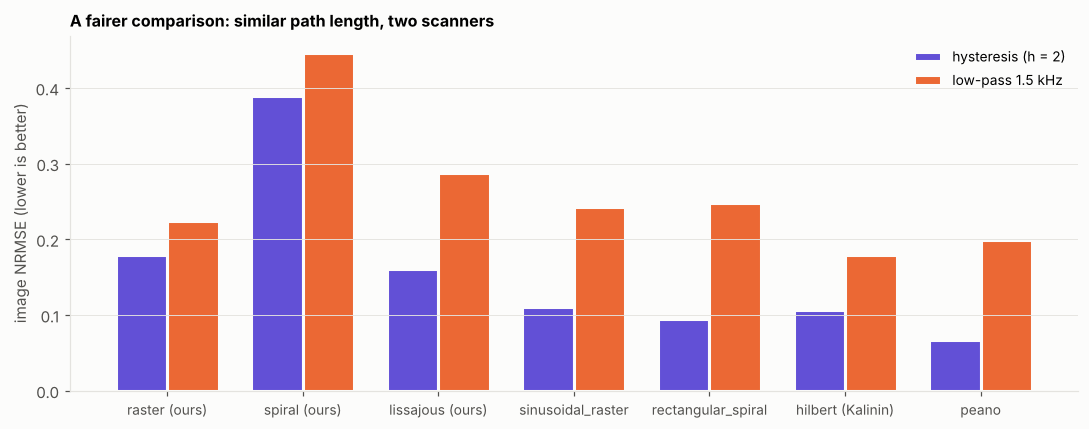

In [12]:
contenders = {
    "raster": {}, "spiral": {}, "lissajous": {"nx": 29, "ny": 30},
    "k_sinusoidal_raster": {"n_lines": 46}, "k_rectangular_spiral": {"n_segments": 190},
    "k_hilbert": {"order": 6}, "k_peano": {"order": 4},
}
scanners = {"hysteresis (h = 2)": scanner, "low-pass 1.5 kHz": ("lowpass", {"bandwidth_hz": 1500})}
wanted = ["image_nrmse", "image_nrmse_oracle", "path_length_um"]
fair = {scan: {name: sp.run((name, p), model, wanted, budget, particles).scores
               for name, p in contenders.items()}
        for scan, model in scanners.items()}

print(f"{'':26s}{'':10s}" + "".join(f"{s:^26s}" for s in scanners))
print(f"{'family':26s}{'length µm':>10s}" + "   as seen   positions known" * 2)
for name in contenders:
    row = f"{label(name):26s}{fair['hysteresis (h = 2)'][name]['path_length_um']:10.1f}"
    for scan in scanners:
        row += f"{fair[scan][name]['image_nrmse']:10.3f}{fair[scan][name]['image_nrmse_oracle']:16.3f}"
    print(row)

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(contenders))
for i, (scan, color) in enumerate(zip(scanners, (VIOLET, ORANGE))):
    ax.bar(x + (i - 0.5) * 0.38, [fair[scan][n]["image_nrmse"] for n in contenders], 0.38,
           color=color, label=scan, edgecolor=SURFACE, linewidth=2)
ax.set_xticks(x, [label(n) for n in contenders], fontsize=9)
ax.set_ylabel("image NRMSE (lower is better)"); ax.grid(axis="x", visible=False)
ax.set_title("A fairer comparison: similar path length, two scanners")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

At similar lengths the space-filling curves hold up well on both scanners. Peano gives the
lowest image error on the hysteresis scanner, and Hilbert (despite being the shortest path
here) is lowest on the low-pass one. The reason is the one we saw on the checkerboard:
they visit the field block by block, so neighbouring points are measured close together in
time and the instrument displaces them together.

The two columns per scanner tell the rest of the story. On the hysteresis scanner, Hilbert
and Peano lose almost nothing to mislabelled positions ("as seen" ≈ "positions known"),
while the rasters and the rectangular spiral lose a third or more of their quality. On the
low-pass scanner everyone loses something, and the paths that sweep long smooth strokes
(Lissajous, the sinusoidal raster, the rectangular spiral) lose the most: their samples
would be roughly twice as good if we knew where they really were.

The rectangular spiral is a nice surprise on the hysteresis scanner. Our round spiral is
held back by something simpler: it only covers the disc in the middle, and the empty
corners count against it.

One honest caveat: this is one synthetic sample and illustrative instrument parameters. It
is a reason to look closer, not a result to publish.

## 8. Closing the loop: the optimizer

So far we've picked parameters by hand. The last stage turns that into a loop: **propose**
parameters, **simulate** the scan, **score** it, **keep the best**, and propose again.
Here it is written out in plain Python, so nothing is hidden. We search Lissajous
frequencies on the 1.5 kHz low-pass scanner, where there's a real trade-off: more cycles
fill the field better but are harder for the scanner to follow.

In [13]:
from math import gcd

rng = np.random.default_rng(1)
scanner_lp = ("lowpass", {"bandwidth_hz": 1500})
best, history = None, []

for step in range(60):
    nx = int(rng.integers(10, 41))                              # 1. propose
    ny = int(rng.integers(10, 41))
    if gcd(nx, ny) != 1:                                        #    (skip paths that retrace)
        continue
    result = sp.run(("lissajous", {"nx": nx, "ny": ny}), scanner_lp,   # 2. simulate
                    ["image_nrmse"], budget, particles)
    score = result.scores["image_nrmse"]                        # 3. score
    if best is None or score < best[0]:                         # 4. keep the best
        best = (score, nx, ny)
        print(f"step {step:2d}: new best  nx = {nx:2d}, ny = {ny:2d}   image NRMSE = {score:.3f}")
    history.append((step, score, best[0]))
print(f"\nafter {len(history)} evaluations: nx = {best[1]}, ny = {best[2]}, NRMSE = {best[0]:.3f}")

step  0: new best  nx = 24, ny = 25   image NRMSE = 0.284


step  8: new best  nx = 29, ny = 27   image NRMSE = 0.283


step 52: new best  nx = 37, ny = 15   image NRMSE = 0.282
step 59: new best  nx = 19, ny = 24   image NRMSE = 0.275

after 37 evaluations: nx = 19, ny = 24, NRMSE = 0.275


Random search is the simplest loop that works, and it's where a smarter optimizer would
slot in later. But for two parameters we can afford to look at *everything*. That's what
`grid_search` does in one line, and the picture it gives is often more useful than the
single best answer.

961 grid points in 42 s; best nx = 32, ny = 11, NRMSE = 0.272


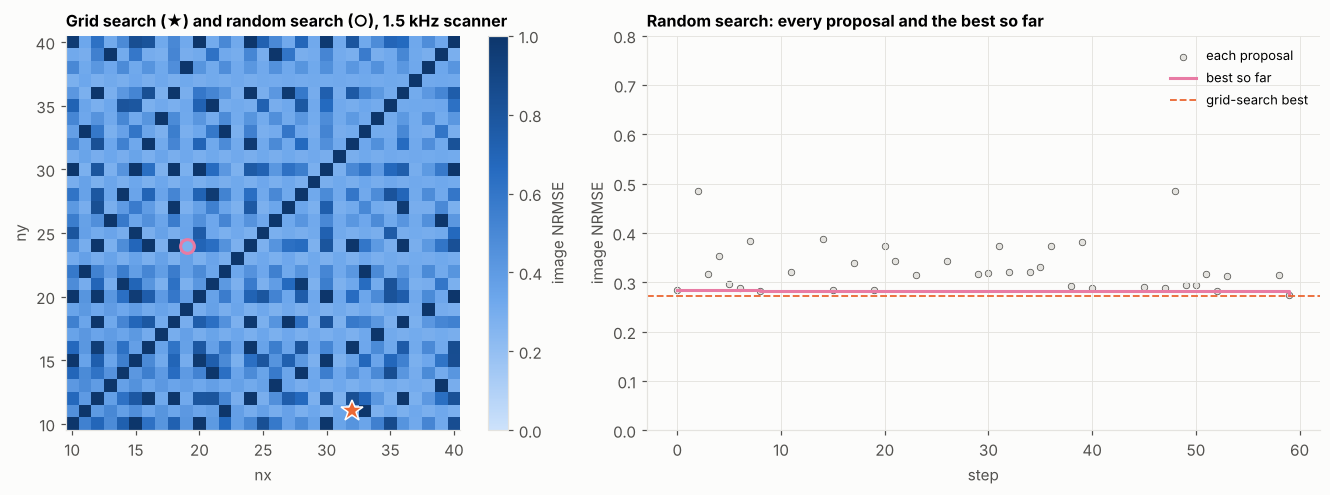

In [14]:
n = np.arange(10, 41)
start = time.time()
rows, top = sp.grid_search("lissajous", {"nx": list(n), "ny": list(n)}, "image_nrmse",
                           instrument=scanner_lp, budget=budget, sample=particles)
print(f"{len(rows)} grid points in {time.time() - start:.0f} s; "
      f"best nx = {top['nx']}, ny = {top['ny']}, NRMSE = {top['image_nrmse']:.3f}")

grid = np.array([r["image_nrmse"] for r in rows]).reshape(len(n), len(n))
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.2]})
im = a.imshow(grid.T, origin="lower", cmap=SEQ, vmin=0, vmax=1,
              extent=[n[0] - 0.5, n[-1] + 0.5, n[0] - 0.5, n[-1] + 0.5])
a.plot(top["nx"], top["ny"], "*", ms=15, color=ORANGE, mec="white")
a.plot(best[1], best[2], "o", ms=9, mfc="none", mec=MAGENTA, mew=2)
a.set_xlabel("nx"); a.set_ylabel("ny"); a.grid(False)
a.set_title("Grid search (★) and random search (○), 1.5 kHz scanner")
fig.colorbar(im, ax=a, fraction=0.046, label="image NRMSE")

steps, scores, running = zip(*history)
b.scatter(steps, scores, s=18, color=GRID, edgecolor=INK2, linewidth=0.5, label="each proposal")
b.step(steps, running, where="post", color=MAGENTA, label="best so far")
b.axhline(top["image_nrmse"], color=ORANGE, ls="--", lw=1.2, label="grid-search best")
b.set_ylim(0, 0.8); b.set_xlabel("step"); b.set_ylabel("image NRMSE")
b.set_title("Random search: every proposal and the best so far"); b.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

The dark diagonal and the scattered dark cells in the heatmap are paths where `nx` and
`ny` share a factor, so the curve closes early and retraces itself. Everything else forms a
broad, fairly flat valley. That is reassuring: the exact choice doesn't matter much, as long
as you avoid the bad ratios and stay in the right range. It also explains why random search
lands close to the grid's best without hitting it exactly.

The best answer depends on the instrument too, and that's the whole point of simulating
it. A raster shows this nicely. Below, we sweep the number of lines on three scanners.

ideal                best lines = 128   NRMSE = 0.028


hysteresis (h = 2)   best lines = 128   NRMSE = 0.097


low-pass 1.5 kHz     best lines =  48   NRMSE = 0.224


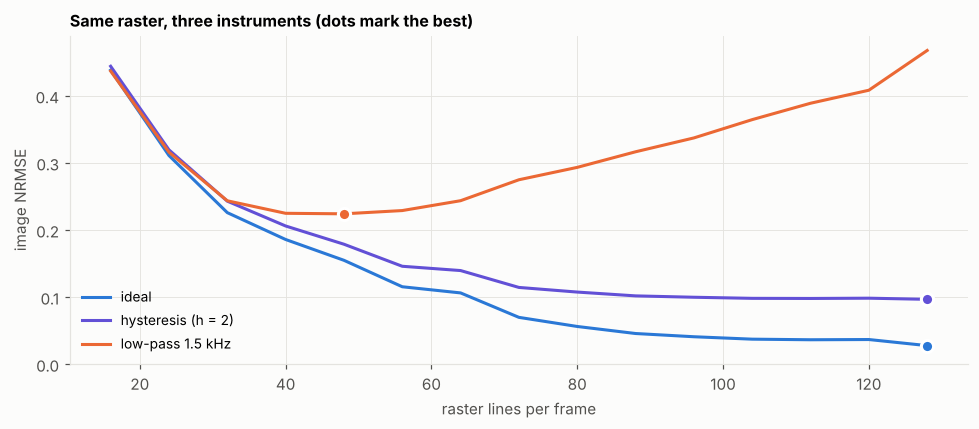

In [15]:
lines = np.arange(16, 129, 8)
fig, ax = plt.subplots(figsize=(9, 4))
for lab, model, color in (("ideal", "ideal", BLUE),
                            ("hysteresis (h = 2)", scanner, VIOLET),
                            ("low-pass 1.5 kHz", scanner_lp, ORANGE)):
    rows, top = sp.grid_search("raster", {"lines": list(lines)}, "image_nrmse",
                               instrument=model, budget=budget, sample=particles)
    ax.plot(lines, [r["image_nrmse"] for r in rows], color=color, label=lab)
    ax.plot(top["lines"], top["image_nrmse"], "o", ms=8, color=color, mec="white", mew=2)
    print(f"{lab:20s} best lines = {top['lines']:3d}   NRMSE = {top['image_nrmse']:.3f}")
ax.set_xlabel("raster lines per frame"); ax.set_ylabel("image NRMSE")
ax.set_ylim(0, None); ax.legend(fontsize=9)
ax.set_title("Same raster, three instruments (dots mark the best)")
plt.tight_layout(); plt.show()

On the ideal scanner, more lines always help. With hysteresis they help until about 100
lines, then the curve goes flat: hysteresis shifts the probe by the same amount however
fast it moves, so that shift sets a floor that denser sampling can't get under. The
low-pass scanner is the one that really pushes back. Beyond about 48 lines, the faster
flybacks cost more than the extra lines gain. Same path family, same score, and the answer
depends entirely on the hardware.

## 9. Adding something new without touching the package

Say a teammate comes in next week with a new idea for a quality measure. They shouldn't
have to edit anybody else's code. Here's a metric written right here in the notebook: the
error that is left after the best affine correction (shift, scale, rotation, shear). That's
the part of the distortion a simple calibration *can't* remove.

In [16]:
@sp.register_metric("affine_residual_nm")
def affine_residual_nm(commanded, realized, sample):
    "RMS error left after the best affine correction: the part calibration can't fix."
    design = np.column_stack((commanded.xy, np.ones(len(commanded.xy))))
    fit, *_ = np.linalg.lstsq(design, realized.xy, rcond=None)
    return np.sqrt(np.mean(np.sum((realized.xy - design @ fit) ** 2, axis=1)))

print(f"{'family':24s}{'rms error nm':>14s}{'after affine nm':>17s}{'fixable':>10s}")
for name, p in contenders.items():
    s = sp.run((name, p), scanner_lp, ["rms_error_nm", "affine_residual_nm"], budget, particles).scores
    fixable = 1 - (s["affine_residual_nm"] / s["rms_error_nm"]) ** 2
    print(f"{label(name):24s}{s['rms_error_nm']:14.3f}{s['affine_residual_nm']:17.3f}{fixable:10.0%}")

family                    rms error nm  after affine nm   fixable
raster (ours)                    1.652            1.649        0%
spiral (ours)                    0.965            0.320       89%
lissajous (ours)                 0.983            0.983        0%
sinusoidal_raster                1.083            1.083        0%
rectangular_spiral               0.967            0.546       68%
hilbert (Kalinin)                0.562            0.561        0%
peano                            0.856            0.855        0%


That's the whole procedure: write a function, put a decorator on it, and every part of the
pipeline (the evaluator, the leaderboard loop, `grid_search`) can use it immediately.

The result is worth a second look. On the low-pass scanner, almost 90% of the round
spiral's error (in squared terms) and about two-thirds of the rectangular spiral's is a
plain rotation and shrink, which a calibration would remove. For every other path the
error is essentially all non-affine and would stay. Plain RMS error can't tell those cases
apart.

## 10. What we've learned, and what's still pretend

**How the pieces connect.** A path family and its parameters go into the generator and come
out as a commanded `Trajectory`. The instrument model turns that into a realized
`Trajectory` on the same clock. Metrics and imaging take both trajectories plus a `Sample`
and return plain numbers and pictures. The optimizer only ever sees those numbers, and
sends back new parameters. Four kinds of object travel between the stages, and that's the
whole contract.

**What the runs suggest.**

* Path length (how hard we drive the scanner) shapes the results as much as the path's
  shape does, so comparisons need to be made at matched length.
* Space-filling curves (Hilbert, Peano) look promising: at matched length they gave the
  lowest image error here on both scanner types, because neighbouring samples are taken
  close together in time.
* Image error has two sources, sparse sampling and mislabelled positions, and the balance
  between them depends on the path and the scanner. Reporting both keeps that visible.
* The best parameters move with the instrument (and a hysteresis scanner doesn't punish
  speed the way a low-pass one does), so the instrument model has to be right before the
  optimizer's answers mean much.

**What's still pretend.** The sample is synthetic, the scanner parameters are illustrative
rather than calibrated, and Kalinin's model steps once per sample rather than in real
seconds. In his generators, the strip families need fixing, and the default Lissajous
should use one period. None of that changes how the pieces fit together, which is what
this notebook was for.